In [1]:
%pip install earthaccess

Note: you may need to restart the kernel to use updated packages.


In [2]:
import earthaccess
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

# settings
YEAR = 2020
start, end = f"{YEAR}-06-01", f"{YEAR}-09-30"   # JJAS
expected = 122                                   # 30 + 31 + 31 + 30 days

raw_dir = Path("data/raw/imerg")
out_dir = Path("data/processed")
raw_dir.mkdir(parents=True, exist_ok=True)
out_dir.mkdir(parents=True, exist_ok=True)

# 1. Log in
# Earthdata username and password the first time.
earthaccess.login(persist=True)

# 2. Search
results = earthaccess.search_data(
    short_name="GPM_3IMERGDF",
    version="07",
    temporal=(start, end),
    bounding_box=(72, 7, 79, 14),   # west, south, east, north,   # west, south, east, north
)
print(f"Files found: {len(results)} (expected {expected})")
assert len(results) == expected, "File count is wrong, check dates/product name"

# 3. Download 
files = earthaccess.download(results, str(raw_dir))
print(f"Files downloaded: {len(files)}")

# 4. Open, crop to Kerala
ds = xr.open_mfdataset(files)
rain = ds["precipitation"]

# Handle ascending or descending latitude
lat_slice = slice(7, 14) if ds.lat[0] < ds.lat[-1] else slice(14, 7)
kerala = rain.sel(lon=slice(72, 79), lat=lat_slice)

# 5. Quick checks
print("Shape (time, lon, lat or similar):", kerala.shape)
print("Min / max (mm/day):", float(kerala.min()), float(kerala.max()))
print("Fraction NaN:", float(kerala.isnull().mean()))

#  6. Save
out_name = f"imerg_kerala_{start}_{end}.nc"
kerala.to_netcdf(out_dir / out_name)
print("Saved:", out_dir / out_name)

Files found: 122 (expected 122)


/Users/jazanowrin/anaconda3/lib/python3.11/site-packages/earthaccess/results.py:343: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
/Users/jazanowrin/anaconda3/lib/python3.11/site-packages/earthaccess/store.py:832: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum(granule.size() for granule in granules) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/122 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/122 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/122 [00:00<?, ?it/s]

Files downloaded: 122
Shape (time, lon, lat or similar): (122, 70, 70)
Min / max (mm/day): 0.0 319.8899841308594
Fraction NaN: 0.0
Saved: data/processed/imerg_kerala_2020-06-01_2020-09-30.nc


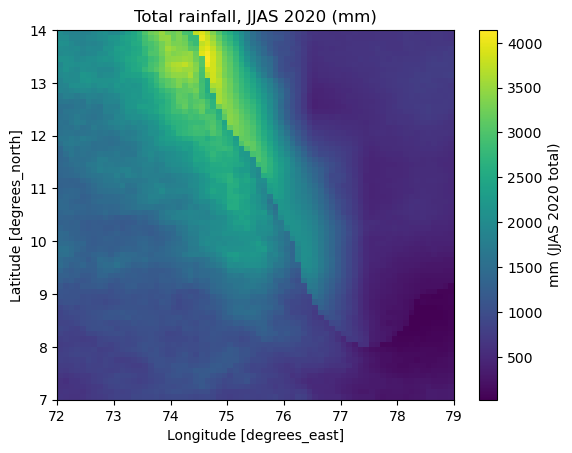

In [3]:
kerala.sum("time").T.plot(cbar_kwargs={"label": "mm (JJAS 2020 total)"})
plt.title("Total rainfall, JJAS 2020 (mm)")
plt.savefig("imerg_jjas2020_total.png", dpi=200, bbox_inches="tight")
plt.show()